In [1]:
import os, sys
REPO = "https://github.com/salsyaniditiani-commits/simuteh--2330511061-.git"

if not os.path.exists("/content/simuteh"):
    !git clone {REPO} /content/simuteh
os.chdir("/content/simuteh")

for f in ["notebook", "hasil", "laporan"]:
    os.makedirs(f, exist_ok=True)

if not os.path.exists("data/sintetis/citra"):
    !python src/buat_dataset_sintetis.py

os.chdir("/content/simuteh/notebook")
sys.path.append("../src")

print("Folder kerja:", os.getcwd())
print("Jumlah citra:", len(os.listdir("../data/sintetis/citra")))
print("Isi src:", os.listdir("../src"))

Cloning into '/content/simuteh'...
remote: Enumerating objects: 115, done.
remote: Counting objects: 100% (115/115), done.
remote: Compressing objects: 100% (97/97), done.
remote: Total 115 (delta 9), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (115/115), 13.43 MiB | 24.17 MiB/s, done.
Resolving deltas: 100% (9/9), done.
Selesai: 60 citra tersimpan di data/sintetis
Folder kerja: /content/simuteh/notebook
Jumlah citra: 60
Isi src: ['praproses.py', 'utils_cv.py', 'buat_dataset_sintetis.py']


KB kanal B   : 2.09
KB kanal G   : 0.80
KB kanal R   : 8.20
KB kanal Gray: 4.20
KB kanal H   : 5.95
KB kanal S   : 1.48
KB kanal V   : 2.09


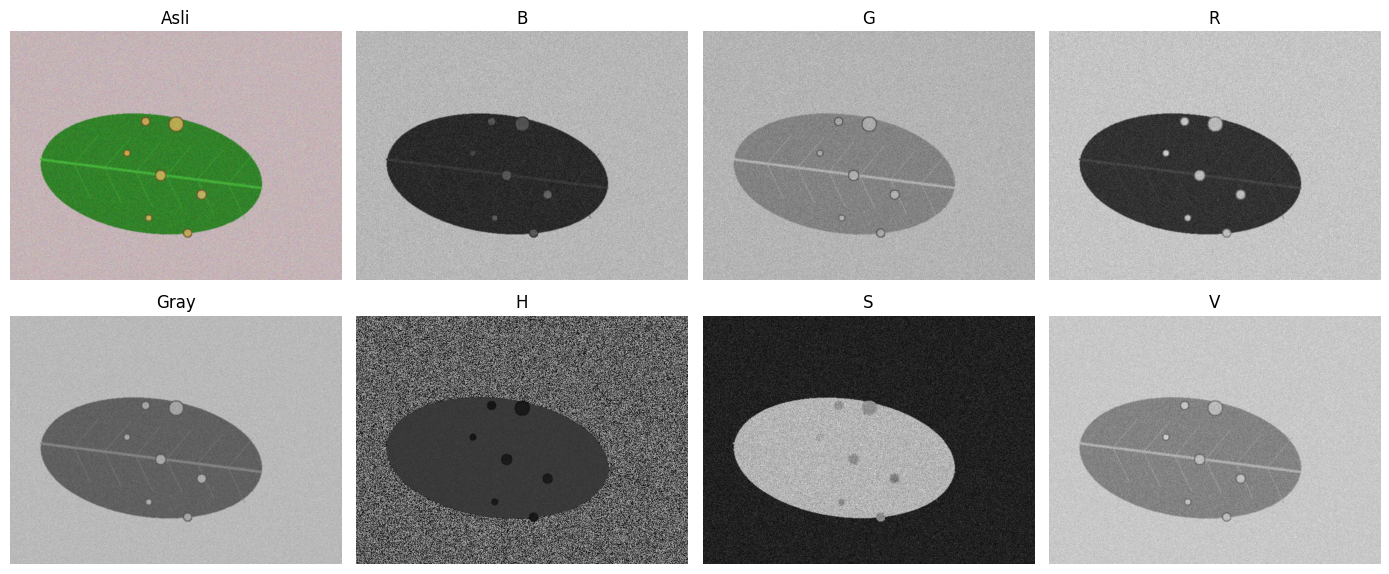

In [2]:
import cv2
from utils_cv import baca, tampil, kontras_bercak

nama = "teh_041.png"                 # kelas berat, kondisi normal
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}

tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()),
       baris=2, ukuran=(14, 6))
for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

In [3]:
# Sampling: perkecil lalu perbesar kembali ke ukuran semula
import numpy as np
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(
        gray,
        None,
        fx=fx,
        fy=fx,
        interpolation=cv2.INTER_AREA
    )

    besar = cv2.resize(
        kecil,
        (gray.shape[1], gray.shape[0]),
        interpolation=cv2.INTER_NEAREST
    )

    kb = kontras_bercak(besar, md, mb)

    print(f"fx={fx}: ukuran {kecil.shape}, KB={kb:.2f}")


# Kuantisasi: sisakan k bit
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)

    kuant = (gray // langkah) * langkah

    jumlah_level = len(np.unique(kuant))
    kb = kontras_bercak(kuant, md, mb)

    print(f"k={k}: {jumlah_level} level, KB={kb:.2f}")

fx=0.5: ukuran (240, 320), KB=5.54
fx=0.2: ukuran (96, 128), KB=4.98
fx=0.1: ukuran (48, 64), KB=3.57
fx=0.05: ukuran (24, 32), KB=1.54
k=1: 2 level, KB=5.19
k=2: 3 level, KB=5.22
k=3: 6 level, KB=2.56
k=4: 11 level, KB=3.82
k=8: 159 level, KB=4.20


In [4]:
import pandas as pd

def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img)
    h, s, v = cv2.split(hsv)

    return {
        "B": b,
        "G": g,
        "R": r,
        "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
        "H": h,
        "S": s,
        "V": v
    }

label = pd.read_csv("../data/sintetis/label.csv")

baris = []

for _, d in label[label.kelas == "berat"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")

    m_d = cv2.imread(
        f"../data/sintetis/mask_daun/{d.nama_file}", 0)

    m_b = cv2.imread(
        f"../data/sintetis/mask_bercak/{d.nama_file}", 0)

    kb = {
        k: kontras_bercak(c, m_d, m_b)
        for k, c in semua_kanal(im).items()}

    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)

# Membuat tabel berdasarkan kondisi pencahayaan
tabel_kb = (
    pd.DataFrame(baris)
    .groupby("kondisi")[["B", "G", "R", "Gray", "H", "S", "V"]]
    .mean()
    .reindex(["normal", "gelap", "terang", "kontras_rendah", "bayangan"])
    .round(2)
)

print(tabel_kb)

# Menyimpan hasil
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")

                   B     G      R  Gray     H     S     V
kondisi                                                  
normal          2.14  1.67  10.95  5.40  8.23  0.98  3.41
gelap           1.11  1.57   9.47  4.65  5.08  0.68  3.36
terang          1.43  0.67   6.14  3.28  4.44  0.55  1.88
kontras_rendah  1.20  0.38   4.25  2.32  2.39  0.24  1.47
bayangan        1.07  0.22   5.39  1.59  4.95  0.74  0.97
